In [53]:
import numpy as np
import random
import matplotlib.pyplot as plt
import time
from IPython.display import clear_output

# Configuración para matplotlib en Colab
%matplotlib inline

In [54]:
# Tamaño del tablero
GRID_SIZE = 9

# Sudoku predefinido (0 representa casillas vacías)
sudoku_puzzle = [
    [5, 3, 0, 0, 7, 0, 0, 0, 0],
    [6, 0, 0, 1, 9, 5, 0, 0, 0],
    [0, 9, 8, 0, 0, 0, 0, 6, 0],
    [8, 0, 0, 0, 6, 0, 0, 0, 3],
    [4, 0, 0, 8, 0, 3, 0, 0, 1],
    [7, 0, 0, 0, 2, 0, 0, 0, 6],
    [0, 6, 0, 0, 0, 0, 2, 8, 0],
    [0, 0, 0, 4, 1, 9, 0, 0, 5],
    [0, 0, 0, 0, 8, 0, 0, 7, 9]
]

In [55]:
# Posiciones de los números fijos
fixed_positions = {(r, c) for r in range(GRID_SIZE) for c in range(GRID_SIZE) if sudoku_puzzle[r][c] != 0}

def draw_grid(grid, generation, fitness_score):
    """Dibuja el Sudoku usando Matplotlib"""
    clear_output(wait=True)
    plt.figure(figsize=(8, 8))
    plt.title(f"Generación: {generation} - Fitness: {fitness_score}", fontsize=14)
    #plt.imshow(np.ones((GRID_SIZE, GRID_SIZE)) * 0.1, cmap="gray", extent=[0, GRID_SIZE, 0, GRID_SIZE])
    plt.gca().set_facecolor((0.8, 0.8, 0.8))  # RGB: 0.8 es un gris claro

    # Dibujar cuadrícula
    for r in range(GRID_SIZE + 1):
        lw = 2 if r % 3 == 0 else 0.5
        plt.plot([0, GRID_SIZE], [r, r], 'k', linewidth=lw)
        plt.plot([r, r], [0, GRID_SIZE], 'k', linewidth=lw)

    # Añadir números
    for r in range(GRID_SIZE):
        for c in range(GRID_SIZE):
            if grid[r][c] != 0:
                color = 'darkred' if (r, c) in fixed_positions else 'darkblue'
                plt.text(c + 0.5, GRID_SIZE - r - 0.5, str(grid[r][c]),
                        ha='center', va='center', fontsize=14, color=color, fontweight='bold')

    plt.xticks([])
    plt.yticks([])
    plt.show()
    plt.close()  # Cerrar figura para liberar memoria

def generate_population(size):
    """Genera población inicial respetando números fijos"""
    pop = []
    for _ in range(size):
        grid = np.array(sudoku_puzzle)
        for r in range(GRID_SIZE):
            missing_in_row = [n for n in range(1, 10) if n not in grid[r]]
            random.shuffle(missing_in_row)
            for c in range(GRID_SIZE):
                if grid[r][c] == 0:
                    grid[r][c] = missing_in_row.pop()
        pop.append(grid)
    return pop

def fitness(grid):
    """Calcula fitness basado en números únicos por filas y columnas"""
    row_unique = sum(len(set(row)) for row in grid)
    col_unique = sum(len(set(col)) for col in grid.T)
    block_unique = 0
    for i in range(3):
        for j in range(3):
            block = grid[i*3:(i+1)*3, j*3:(j+1)*3].flatten()
            block_unique += len(set(block))
    return row_unique + col_unique + block_unique

def crossover(p1, p2):
    """Cruzamiento por filas con probabilidad 50%"""
    mask = np.random.rand(9) < 0.5
    child = np.where(mask[:, None], p1, p2)
    return child

def mutate(grid, mutation_rate=0.05):
    """Mutación haciendo swaps entre los hijos de la misma fila, respetando posiciones fijas asi las filas siempre cumplen la regla"""
    new_grid = grid.copy()
    rows = [r for r in range(GRID_SIZE) if random.random() < mutation_rate]
    if not rows:
        rows = [random.randrange(GRID_SIZE)]
    for r in rows:
        mutable_indices = [c for c in range(GRID_SIZE) if (r, c) not in fixed_positions]
        if len(mutable_indices) >= 2:
            c1, c2 = random.sample(mutable_indices, 2)
            new_grid[r][c1], new_grid[r][c2] = new_grid[r][c2], new_grid[r][c1]
    return new_grid

def genetic_algorithm(pop_size=100, max_generations=1000, mutation_rate=0.05):
    """Algoritmo genético principal"""
    population = generate_population(pop_size)
    generations_count_without_improvement = 0
    best_ever, best_ever_fitness = None, 0

    for generation in range(max_generations):
        # Evaluar y ordenar población
        population.sort(key=lambda x: -fitness(x))
        best_solution = population[0]
        current_fitness = fitness(best_solution)

        # Mostrar progreso cada 10 generaciones
        if generation % 10 == 0:
            draw_grid(best_solution, generation, current_fitness)
            print(f"Generación: {generation:4d} | Fitness: {current_fitness:3d} | "
                  f"Mejor histórico: {best_ever_fitness:3d} | Máximo posible: 243")
            time.sleep(0.1)
        
        if current_fitness == 243:
            print("\n¡Sudoku resuelto!")
            draw_grid(best_solution, generation, current_fitness)
            return best_solution

        if current_fitness <= best_ever_fitness:
            generations_count_without_improvement += 1
        else:
            generations_count_without_improvement = 0
            best_ever_fitness = current_fitness
            best_ever = best_solution.copy()


        if generations_count_without_improvement >= 150:
            print("\nNo hay mejora en 150 generaciones. Reiniciando población...")
            population = generate_population(pop_size)
            generations_count_without_improvement = 0
            continue

        # Selección y reproducción
        parents = population[:pop_size//2]  # Seleccionar mejores 50%
        new_pop = [best_solution.copy()]

        while len(new_pop) < pop_size:
            p1, p2 = random.choices(parents, k=2)
            child = mutate(crossover(p1, p2), mutation_rate)
            new_pop.append(child)

        population = new_pop

    print("\nMáximo de generaciones alcanzado. Solución no encontrada.")
    draw_grid(best_ever, max_generations, best_ever_fitness)
    return best_ever


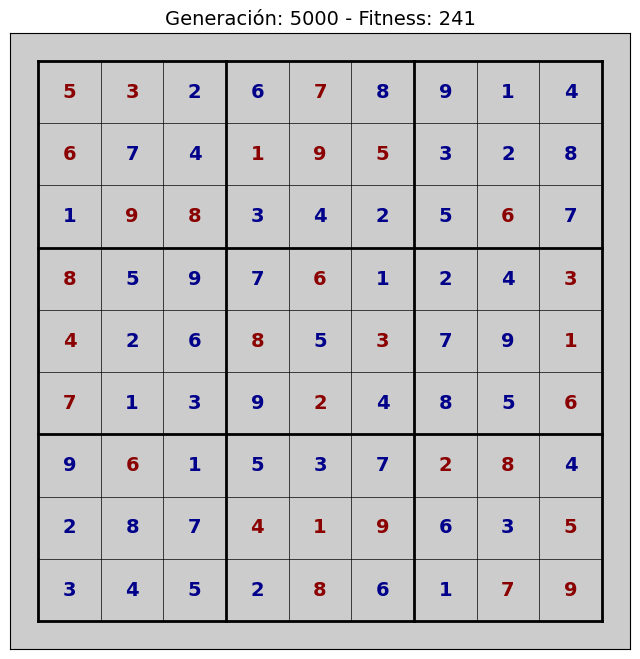

array([[5, 3, 2, 6, 7, 8, 9, 1, 4],
       [6, 7, 4, 1, 9, 5, 3, 2, 8],
       [1, 9, 8, 3, 4, 2, 5, 6, 7],
       [8, 5, 9, 7, 6, 1, 2, 4, 3],
       [4, 2, 6, 8, 5, 3, 7, 9, 1],
       [7, 1, 3, 9, 2, 4, 8, 5, 6],
       [9, 6, 1, 5, 3, 7, 2, 8, 4],
       [2, 8, 7, 4, 1, 9, 6, 3, 5],
       [3, 4, 5, 2, 8, 6, 1, 7, 9]])

In [58]:
# Ejecutar el algoritmo con parámetros ajustados
genetic_algorithm(pop_size=100, max_generations=5000, mutation_rate=0.2)